# 05 · Graph lab

Earlier graph tries (notebooks 03 and 04) were only **averages over neighbours**: author-mention graph (mean views of the same author), text-similarity kNN graph (mean views and smoothed engagement of the nearest mentions) and a brand-similarity graph. That is a narrow test, so here graphs get their own notebook with more unconventional ideas.

**A. Can graphs improve the views estimate?** Same base (extra trees on followers + engagement), same brand-grouped CV, paired bootstrap gain. Variants:
- label-free graph features: communities (Louvain), PageRank, clustering, near-duplicate counts, spectral node embedding, author-brand bipartite graph
- target-based encodings from the training fold only: community mean residual, brand-community mean residual, hashtag graph, time graph, near-duplicate graph, label propagation, category encodings

**B. What does the graph tell us about the mentions themselves?** Homophily of our type labels, community profiles, near-duplicate campaigns, and predicting the type label from the graph.

In [1]:
import sys, json, warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw" / "reach_samples_students.csv").exists())
sys.path.insert(0, str(ROOT / "src"))
import eda_utils as eu, modeling as mo, extra_models as em, graph_lab as gl

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 220, "display.max_columns", 30, "display.max_colwidth", 70)

In [2]:
f, meta = em.load(ROOT)
raw = eu.load(ROOT).astype({'mention_id': str})
Ps = {p: gl.prepare(f, meta, raw, p) for p in mo.PLATS}
labs = {p: gl.labels_for(meta[meta.platform == p], ROOT) for p in mo.PLATS}

In [3]:
pd.DataFrame({eu.NAMES[p]: {'mentions (nodes)': len(P['M']), 'text-graph edges (kNN, k=10)': int((np.triu(P['A']) > 0).sum()), 'Louvain communities': len(set(P['comm'])), 'brands': P['M'].brand.nunique(), 'brand communities': len(set(P['bcomm']))} for p, P in Ps.items()})

,TikTok,YouTube,X (Twitter)
mentions (nodes),2491,2441,1803
"text-graph edges (kNN, k=10)",17179,17656,12886
Louvain communities,37,29,27
brands,266,273,252
brand communities,11,12,13


In [4]:
Ps['twitter']['free']['structure'].head()

,comm_size,strength,pagerank,clustering,near_dups,max_sim
0,2.086360,3.837606,1.439184,0.084174,1,0.643881
1,1.681241,1.875955,0.825069,0.022831,0,0.182854
2,2.086360,3.158917,1.200438,0.112999,1,0.976156
3,2.086360,3.085073,1.167156,0.133448,2,0.976156
4,2.017033,3.044023,1.189846,0.044004,0,0.380333


## A · Graph variants vs the engagement-only base
Gain = mean of |error base| minus |error variant| per mention (positive = better), 95% brand-cluster bootstrap CI.

In [5]:
res = pd.concat([gl.evaluate(P, p) for p, P in Ps.items()], ignore_index=True)
res.pivot(index='model', columns='platform', values='MAE').reindex(res.model.unique()).round(3)

platform,TikTok,X (Twitter),YouTube
model,,,
base: followers + engagement,0.277,0.481,0.455
+ structure,0.278,0.483,0.453
+ spectral,0.278,0.477,0.449
+ author graph,0.279,0.486,0.458
+ all label-free graph features,0.278,0.479,0.452
+ community mean residual,0.278,0.477,0.455
+ brand-community mean residual,0.279,0.477,0.456
+ hashtag graph,0.277,0.478,0.453
+ time graph (+-3 days),0.277,0.480,0.458


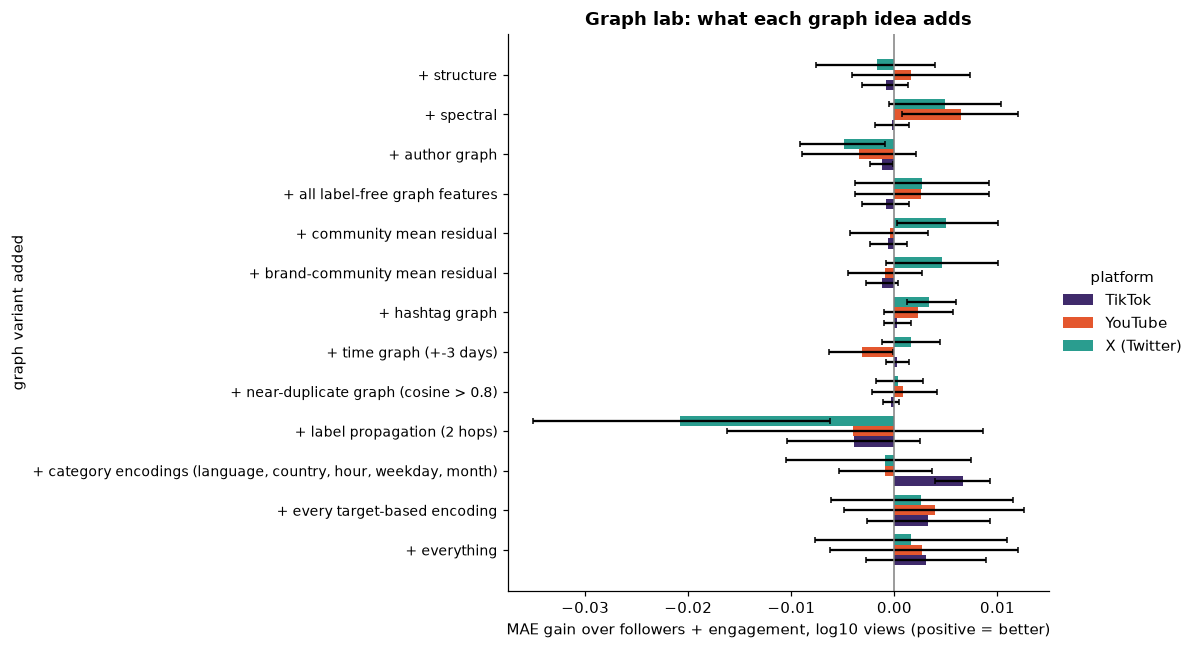

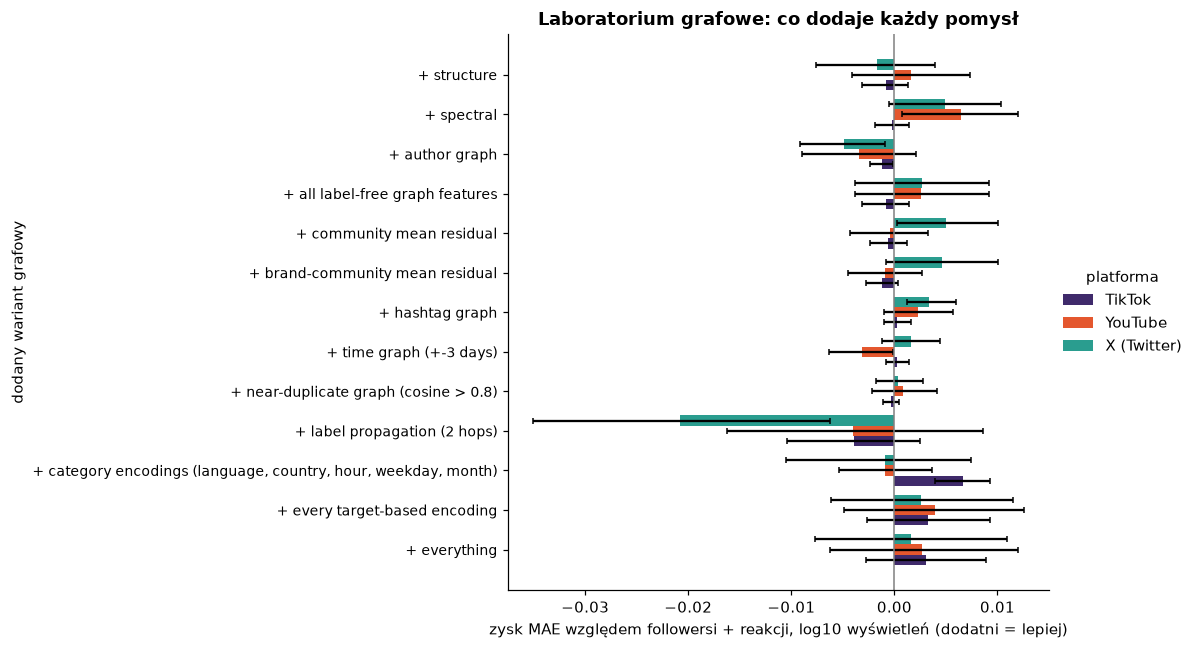

In [6]:
gl.plot_variants(res, ROOT / 'figures' / 'graphlab_gains_en.png', 'en'); gl.plot_variants(res, ROOT / 'figures' / 'graphlab_gains_pl.png', 'pl')

In [7]:
res[~res.model.str.startswith('base')][['platform', 'model', 'gain vs base', 'gain low', 'gain high']].round(3).reset_index(drop=True)

,platform,model,gain vs base,gain low,gain high
0,TikTok,+ structure,-0.001,-0.003,0.001
1,TikTok,+ spectral,-0.000,-0.002,0.001
2,TikTok,+ author graph,-0.001,-0.002,-0.000
3,TikTok,+ all label-free graph features,-0.001,-0.003,0.001
4,TikTok,+ community mean residual,-0.001,-0.002,0.001
5,TikTok,+ brand-community mean residual,-0.001,-0.003,0.000
6,TikTok,+ hashtag graph,0.000,-0.001,0.002
7,TikTok,+ time graph (+-3 days),0.000,-0.001,0.001
8,TikTok,+ near-duplicate graph (cosine > 0.8),-0.000,-0.001,0.000
9,TikTok,+ label propagation (2 hops),-0.004,-0.010,0.003


Takeaway A: no graph idea gives more than about 0.007 (log10) in the MAE, and several are slightly negative. Label propagation hurts on all platforms (X -0.021): on the training fold it sees residuals reflected through loops. Best single gains are tiny: category encodings on TikTok (+0.007, CI above zero), spectral embedding on YouTube (+0.006) and communities on X (+0.005, CI touches zero). The signal is in engagement, not in the graph.

## B1 · Does the text graph know our labels? (homophily)
Share of graph edges joining mentions with the same type label, against the share expected by chance, and the assortativity coefficient.

In [8]:
hom = pd.DataFrame([gl.homophily(Ps[p], labs[p], p) for p in mo.PLATS]); hom.round(3)

,platform,same-type edges,expected by chance,assortativity
0,TikTok,0.461,0.359,0.162
1,YouTube,0.451,0.309,0.205
2,X (Twitter),0.654,0.523,0.263


Takeaway B1: the text graph clearly knows our labels: same-type edges are 65% on X against 52% by chance (assortativity 0.26), 45-46% against 31-36% on TikTok and YouTube.

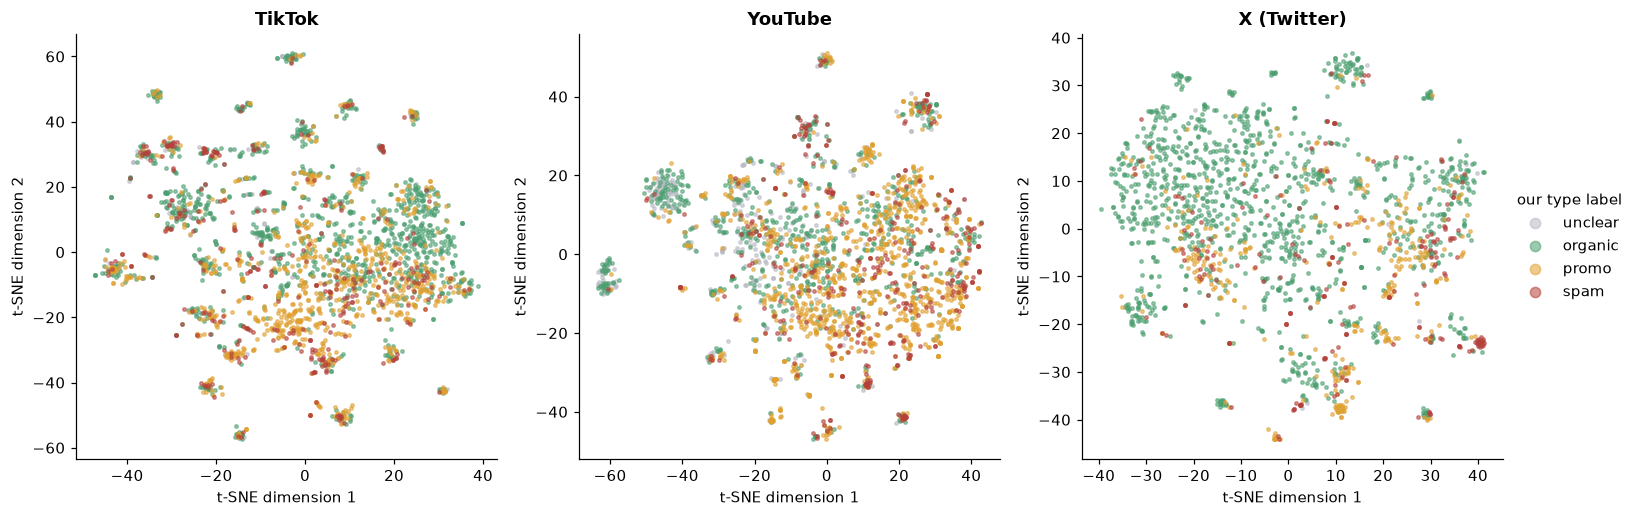

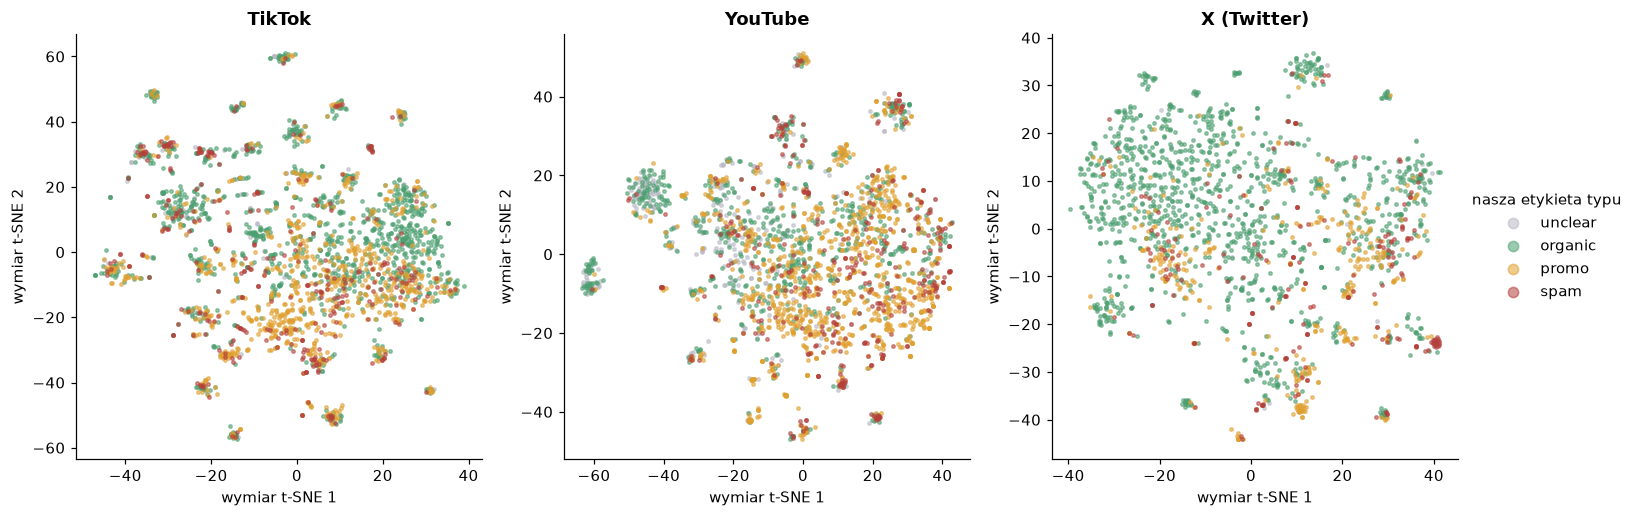

In [9]:
gl.plot_map(Ps, labs, ROOT / 'figures' / 'graphlab_map_en.png', 'en'); gl.plot_map(Ps, labs, ROOT / 'figures' / 'graphlab_map_pl.png', 'pl')

Takeaway B1b: on the t-SNE map organic mentions spread widely, while promo and spam form tight clusters of near-identical posts.

## B2 · What are the communities?
Louvain communities of the text graph with at least 25 mentions: top terms, our type mix, median log10 views.

In [10]:
prof = pd.concat([gl.community_profile(Ps[p], labs[p], p) for p in mo.PLATS], ignore_index=True)
prof.groupby('platform', sort=False).head(6).round(2)

,platform,community,size,top terms,organic,promo,spam,median log10 views,brands
0,TikTok,29,250,"lexus, car, toyota, cars, ford",0.35,0.47,0.12,2.86,59
1,TikTok,24,182,"hotel, whirlpool, inn, airbnb, hyatt",0.42,0.47,0.09,2.76,54
2,TikTok,17,138,"com, https, www, fedex, twitch",0.28,0.48,0.24,2.57,51
3,TikTok,1,137,"airlines, delta, shoprite, alaska, kayak",0.57,0.25,0.12,2.97,33
4,TikTok,32,127,"samsung, asus, galaxy, ram, laptop",0.26,0.53,0.17,3.02,30
5,TikTok,34,106,"priceline, hertz, skincare, body, australia",0.40,0.46,0.09,2.73,32
35,YouTube,13,369,"https, com, www, instagram, facebook",0.24,0.51,0.24,2.98,121
36,YouTube,15,307,"gt, 039, costco, little, chipotle",0.46,0.10,0.04,2.51,83
37,YouTube,6,169,"https, com, www, amazon, shop",0.33,0.51,0.11,2.95,73
38,YouTube,11,150,"jobs, https, ai, 2025, com",0.12,0.57,0.26,2.12,52


Takeaway B2: communities are mostly industries (cars, banks, fast food, airlines) and some are link-heavy promo or spam groups; their views differ by platform, not by community.

## B3 · Near-duplicates (copy-paste campaigns)
Mentions with a near-identical text (cosine > 0.8): how many, how spammy, and do duplicates get similar views?

In [11]:
dup = pd.DataFrame([gl.duplicates(Ps[p], labs[p], p) for p in mo.PLATS]); dup.round(3)

,platform,share with near-duplicate,"spam share, duplicates","spam share, others",pairs,"corr of log views, duplicate pairs","corr of log views, random pairs"
0,TikTok,0.056,0.257,0.125,92,0.665,-0.205
1,YouTube,0.137,0.245,0.137,337,0.818,0.077
2,X (Twitter),0.090,0.383,0.091,129,0.785,0.082


Takeaway B3: 6-14% of mentions have a near-identical copy. Among them spam is two to four times more frequent, and the log views of duplicate pairs correlate 0.67-0.82 against about 0 for random pairs. Too few mentions have a duplicate in another brand for this to improve the estimate.

## B4 · Predicting the type label from the graph
Organic / promo / spam, brand-grouped CV, macro F1. Text-only logistic regression on TF-IDF vs adding a vote of the most similar training mentions.

In [12]:
typ = pd.concat([gl.predict_type(Ps[p], labs[p], p) for p in mo.PLATS], ignore_index=True)
typ.pivot(index='model', columns='platform', values='macro F1').round(3)

platform,TikTok,X (Twitter),YouTube
model,,,
graph vote only,0.473,0.503,0.545
text + graph vote,0.546,0.570,0.594
text only,0.567,0.630,0.615


Takeaway B4: the graph vote does not help to predict the type label. Text alone is best (macro F1 0.57 TikTok, 0.62 YouTube, 0.63 X).

In [13]:
out = {"variants": res.to_dict("records"), "homophily": hom.to_dict("records"), "duplicates": dup.to_dict("records"), "type_prediction": typ.to_dict("records"), "communities": prof.to_dict("records")}
json.dump(out, open(ROOT / "data" / "processed" / "graphlab_numbers.json", "w"), indent=1, default=float)